<a href="https://colab.research.google.com/github/GilbertOwen/reefscan-id/blob/stage1-baseline/notebooks/07_stage1_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ReefScan-ID: Stage 1 baseline (E1)

A small U-Net trained from scratch, compared with the pretrained SegFormer-B0 of notebook 02 on the Coralscapes validation set. The data, class mapping, crops, loss and scoring are the same as in notebook 02. The test split is not used. Run in Google Colab with a GPU runtime.

### Setup: Colab runtime and Google Drive

In [17]:
import os
import torch
from google.colab import drive

drive.mount("/content/drive")

device = "cuda" if torch.cuda.is_available() else "cpu"
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
print("GPU: {}".format(gpu_name))
print("CPU count: {}".format(os.cpu_count()))

base_dir = "/content/drive/MyDrive/ReefScan-ID"
print("Drive folder found: {}".format(os.path.isdir(base_dir)))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4
CPU count: 2
Drive folder found: True


### Setup: libraries

In [18]:
!pip install -q datasets
import random
import time
import numpy as np
from PIL import Image

import datasets
print("torch version: {}".format(torch.__version__))
print("datasets version: {}".format(datasets.__version__))
print("numpy version: {}".format(np.__version__))

torch version: 2.14.1+cu130
datasets version: 4.8.5
numpy version: 2.4.6


### Settings

The learning rate is for a model trained from scratch. Notebook 02 used 6e-5 because its encoder was pretrained. The weight decay, the crop size, the batch size and the validation size are the same as in notebook 02.

In [19]:
crop_size = 512
batch_size = 8
num_workers = 2
val_height = 512
val_width = 1024
val_batch_size = 4
seed = 0

base_width = 32
levels = 4
learning_rate = 1e-3
weight_decay = 0.01
timing_steps = 30

# Reference values printed by notebook 02
segformer_params = 3714915
segformer_pixels = 3181379584
image_mean_values = [0.485, 0.456, 0.406]
image_std_values = [0.229, 0.224, 0.225]

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

print("Crops: {} by {}, batch size {}, workers {}".format(crop_size, crop_size, batch_size, num_workers))
print("Validation photos resized to {} by {}, batch size {}".format(val_height, val_width, val_batch_size))
print("U-Net: {} levels, base width {}".format(levels, base_width))
print("Optimiser for the baseline: AdamW, learning rate {}, weight decay {}, linear decay to 0".format(
    learning_rate, weight_decay))
print("Notebook 02 used: AdamW, learning rate 6e-05, weight decay 0.01, linear decay to 0")

Crops: 512 by 512, batch size 8, workers 2
Validation photos resized to 512 by 1024, batch size 4
U-Net: 4 levels, base width 32
Optimiser for the baseline: AdamW, learning rate 0.001, weight decay 0.01, linear decay to 0
Notebook 02 used: AdamW, learning rate 6e-05, weight decay 0.01, linear decay to 0


## Section 1: Data and model

Question: does the baseline see the same data, class mapping, crops, loss and scoring as the SegFormer-B0 run of notebook 02, how large is the U-Net next to SegFormer-B0, and how long does one epoch take on this GPU?

Checks: load Coralscapes from the Drive cache, rebuild the class mapping and the class weights, build the crop and validation loaders, build the U-Net and print its parameter count, run one forward pass, score the untrained model once, then time 30 training steps and one validation pass to estimate the seconds per epoch. Only the train and validation splits are used.

### Load the dataset

In [20]:
raw_dir = base_dir + "/RawData"

from datasets import load_dataset

print("Cache folder exists: {}".format(os.path.isdir(raw_dir)))

start = time.time()
ds = load_dataset("EPFL-ECEO/coralscapes", cache_dir=raw_dir)
print(ds)
print("Loading took {:.1f} seconds".format(time.time() - start))

Cache folder exists: True
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 1517
    })
    validation: Dataset({
        features: ['image', 'label'],
        num_rows: 166
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 392
    })
})
Loading took 2.4 seconds


### Class names from the dataset card

Ids and names copied from notebook 02, which copied them from the table on the Coralscapes dataset card.

In [21]:
class_names = {
    1: "seagrass",
    2: "trash",
    3: "other coral dead",
    4: "other coral bleached",
    5: "sand",
    6: "other coral alive",
    7: "human",
    8: "transect tools",
    9: "fish",
    10: "algae covered substrate",
    11: "other animal",
    12: "unknown hard substrate",
    13: "background",
    14: "dark",
    15: "transect line",
    16: "massive/meandering bleached",
    17: "massive/meandering alive",
    18: "rubble",
    19: "branching bleached",
    20: "branching dead",
    21: "millepora",
    22: "branching alive",
    23: "massive/meandering dead",
    24: "clam",
    25: "acropora alive",
    26: "sea cucumber",
    27: "turbinaria",
    28: "table acropora alive",
    29: "sponge",
    30: "anemone",
    31: "pocillopora alive",
    32: "table acropora dead",
    33: "meandering bleached",
    34: "stylophora alive",
    35: "sea urchin",
    36: "meandering alive",
    37: "meandering dead",
    38: "crown of thorn",
    39: "dead clam",
}

print("Classes on the card: {}".format(len(class_names)))

Classes on the card: 39


### Build the mapping array

In [22]:
coral_ids = [3, 4, 6, 16, 17, 19, 20, 21, 22, 23, 25, 27, 28, 31, 32, 33, 34, 36, 37]
substrate_ids = [5, 10, 12, 18]
group_names = {0: "coral", 1: "substrate", 2: "other"}
ignore_id = 255

# Values that are not on the card stay at the ignore id
mapping = np.full(256, ignore_id, dtype=np.uint8)
for value in class_names:
    mapping[value] = 2
mapping[coral_ids] = 0
mapping[substrate_ids] = 1

for group_id, group_name in group_names.items():
    names = [class_names[v] for v in class_names if mapping[v] == group_id]
    print("{} ({} ids): {}".format(group_name, len(names), names))
print("Mask value 0 maps to: {}".format(mapping[0]))

coral (19 ids): ['other coral dead', 'other coral bleached', 'other coral alive', 'massive/meandering bleached', 'massive/meandering alive', 'branching bleached', 'branching dead', 'millepora', 'branching alive', 'massive/meandering dead', 'acropora alive', 'turbinaria', 'table acropora alive', 'pocillopora alive', 'table acropora dead', 'meandering bleached', 'stylophora alive', 'meandering alive', 'meandering dead']
substrate (4 ids): ['sand', 'algae covered substrate', 'unknown hard substrate', 'rubble']
other (16 ids): ['seagrass', 'trash', 'human', 'transect tools', 'fish', 'other animal', 'background', 'dark', 'transect line', 'clam', 'sea cucumber', 'sponge', 'anemone', 'sea urchin', 'crown of thorn', 'dead clam']
Mask value 0 maps to: 255


### Count train pixels per mask value

In [23]:
pixel_counts = {}

start = time.time()
counts = np.zeros(256, dtype=np.int64)
masks = ds["train"].select_columns(["label"])
for row in masks:
    mask = np.array(row["label"])
    counts += np.bincount(mask.ravel(), minlength=256)
pixel_counts["train"] = counts

print("train: {} masks counted, {} pixels, {:.0f} seconds".format(masks.num_rows, counts.sum(), time.time() - start))
print("Same pixel total as notebook 02: {}".format(int(counts.sum()) == segformer_pixels))

train: 1517 masks counted, 3181379584 pixels, 32 seconds
Same pixel total as notebook 02: True


### Class weights and loss

In [24]:
train_counts = pixel_counts["train"]
group_pixels = np.array([train_counts[mapping == group_id].sum() for group_id in group_names])
group_share = group_pixels / group_pixels.sum()
class_weights = 1 / group_share
class_weights = class_weights / class_weights.mean()

for group_id, group_name in group_names.items():
    print("{}: {:.2f}% of labelled train pixels, weight {:.3f}".format(
        group_name, 100 * group_share[group_id], class_weights[group_id]))
print("Same weights as notebook 02 (1.076, 1.000, 0.924): {}".format(
    bool(np.allclose(class_weights.round(3), [1.076, 1.0, 0.924]))))

weight_tensor = torch.tensor(class_weights, dtype=torch.float32, device=device)


def segmentation_loss(logits, masks):
    upsampled = torch.nn.functional.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)
    return torch.nn.functional.cross_entropy(upsampled, masks, weight=weight_tensor, ignore_index=ignore_id)

coral: 30.87% of labelled train pixels, weight 1.076
substrate: 33.19% of labelled train pixels, weight 1.000
other: 35.94% of labelled train pixels, weight 0.924
Same weights as notebook 02 (1.076, 1.000, 0.924): True


### Crop dataset class

In [25]:
import random
from torch.utils.data import Dataset

crop_size = 512


class CropDataset(Dataset):
    def __init__(self, split, crop_size, flip):
        self.split = split
        self.crop_size = crop_size
        self.flip = flip

    def __len__(self):
        return self.split.num_rows

    def __getitem__(self, index):
        row = self.split[index]
        image = np.array(row["image"])
        mask = mapping[np.array(row["label"])]

        # Same random window for the image and the mask
        top = random.randint(0, image.shape[0] - self.crop_size)
        left = random.randint(0, image.shape[1] - self.crop_size)
        image = image[top:top + self.crop_size, left:left + self.crop_size]
        mask = mask[top:top + self.crop_size, left:left + self.crop_size]

        if self.flip and random.random() < 0.5:
            image = image[:, ::-1]
            mask = mask[:, ::-1]

        image = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255
        mask = torch.from_numpy(mask.copy()).long()
        return image, mask


print("Crop size: {}".format(crop_size))

Crop size: 512


### Validation dataset class

In [26]:
class ResizeDataset(Dataset):
    def __init__(self, split, height, width):
        self.split = split
        self.height = height
        self.width = width

    def __len__(self):
        return self.split.num_rows

    def __getitem__(self, index):
        row = self.split[index]
        image = row["image"].resize((self.width, self.height), Image.BILINEAR)
        label = row["label"].resize((self.width, self.height), Image.NEAREST)
        image = torch.from_numpy(np.array(image)).permute(2, 0, 1).float() / 255
        mask = torch.from_numpy(mapping[np.array(label)]).long()
        return image, mask


print("Validation dataset class defined")

Validation dataset class defined


### Data loaders

In [27]:
from torch.utils.data import DataLoader

train_data = CropDataset(ds["train"], crop_size, flip=True)
eval_data = ResizeDataset(ds["validation"], val_height, val_width)
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=num_workers)
eval_loader = DataLoader(eval_data, batch_size=val_batch_size, shuffle=False, num_workers=num_workers)

print("Train crops per epoch: {}, batches: {}".format(len(train_data), len(train_loader)))
print("Validation photos: {}, batches: {}".format(len(eval_data), len(eval_loader)))

for name, loader in [("train", train_loader), ("validation", eval_loader)]:
    images, masks = next(iter(loader))
    print("{} batch: images {}, dtype {}, min {:.3f}, max {:.3f}".format(
        name, tuple(images.shape), images.dtype, images.min().item(), images.max().item()))
    print("{} batch: masks {}, dtype {}, values {}".format(
        name, tuple(masks.shape), masks.dtype, torch.unique(masks).tolist()))

Train crops per epoch: 1517, batches: 190
Validation photos: 166, batches: 42
train batch: images (8, 3, 512, 512), dtype torch.float32, min 0.000, max 1.000
train batch: masks (8, 512, 512), dtype torch.int64, values [0, 1, 2, 255]
validation batch: images (4, 3, 512, 1024), dtype torch.float32, min 0.000, max 1.000
validation batch: masks (4, 512, 1024), dtype torch.int64, values [0, 1, 2, 255]


### U-Net

Each level has two 3 by 3 convolutions with batch normalisation and ReLU. The encoder halves the size with max pooling between levels, the decoder doubles it with a transposed convolution and joins the skip connection of the same level. The widths double from level to level, starting at the base width.

In [28]:
from torch import nn


class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels, num_classes, base_width, levels):
        super().__init__()
        widths = [base_width * 2 ** level for level in range(levels)]
        self.encoders = nn.ModuleList([DoubleConv(in_channels, widths[0])])
        for level in range(1, levels):
            self.encoders.append(DoubleConv(widths[level - 1], widths[level]))
        self.pool = nn.MaxPool2d(2)

        self.ups = nn.ModuleList()
        self.decoders = nn.ModuleList()
        for level in range(levels - 1, 0, -1):
            self.ups.append(nn.ConvTranspose2d(widths[level], widths[level - 1], 2, stride=2))
            self.decoders.append(DoubleConv(widths[level - 1] * 2, widths[level - 1]))
        self.head = nn.Conv2d(widths[0], num_classes, 1)

    def forward(self, x):
        skips = []
        for level, encoder in enumerate(self.encoders):
            x = encoder(x)
            if level < len(self.encoders) - 1:
                skips.append(x)
                x = self.pool(x)
        for up, decoder, skip in zip(self.ups, self.decoders, reversed(skips)):
            x = up(x)
            x = decoder(torch.cat([skip, x], dim=1))
        return self.head(x)


model = UNet(3, len(group_names), base_width, levels).to(device)

image_mean = torch.tensor(image_mean_values, device=device).view(1, 3, 1, 1)
image_std = torch.tensor(image_std_values, device=device).view(1, 3, 1, 1)


def normalise(images):
    return (images - image_mean) / image_std


total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Level widths: {}".format([base_width * 2 ** level for level in range(levels)]))
print("U-Net parameters: {} total, {} trainable".format(total_params, trainable_params))
print("SegFormer-B0 parameters printed by notebook 02: {}".format(segformer_params))
print("U-Net parameters divided by SegFormer-B0 parameters: {:.2f}".format(total_params / segformer_params))

Level widths: [32, 64, 128, 256]
U-Net parameters: 1927075 total, 1927075 trainable
SegFormer-B0 parameters printed by notebook 02: 3714915
U-Net parameters divided by SegFormer-B0 parameters: 0.52


### One forward pass

In [29]:
images, masks = next(iter(train_loader))

model.eval()
with torch.no_grad():
    logits = model(normalise(images.to(device)))

print("Input shape: {}".format(tuple(images.shape)))
print("Logits shape: {}".format(tuple(logits.shape)))
print("Logits have the size of the masks: {}".format(tuple(logits.shape[-2:]) == tuple(masks.shape[-2:])))

Input shape: (8, 3, 512, 512)
Logits shape: (8, 3, 512, 512)
Logits have the size of the masks: True


### Validation metrics

In [30]:
group_count = len(group_names)


def evaluate(model, loader):
    confusion = torch.zeros(group_count, group_count, dtype=torch.int64, device=device)
    model.eval()
    with torch.no_grad():
        for images, masks in loader:
            masks = masks.to(device)
            logits = model(normalise(images.to(device)))
            upsampled = torch.nn.functional.interpolate(logits, size=masks.shape[-2:], mode="bilinear", align_corners=False)
            predicted = upsampled.argmax(dim=1)

            # Pixels with the ignore id are left out
            keep = masks != ignore_id
            pairs = masks[keep] * group_count + predicted[keep]
            confusion += torch.bincount(pairs, minlength=group_count ** 2).reshape(group_count, group_count)

    intersection = confusion.diag().float()
    union = confusion.sum(dim=0).float() + confusion.sum(dim=1).float() - intersection
    return (intersection / union).cpu().numpy()


start = time.time()
iou = evaluate(model, eval_loader)
print("Model before training")
for group_id, group_name in group_names.items():
    print("{} IoU: {:.4f}".format(group_name, iou[group_id]))
print("mIoU: {:.4f}".format(iou.mean()))
print("One validation pass took {:.1f} seconds".format(time.time() - start))

Model before training
coral IoU: 0.2276
substrate IoU: 0.0000
other IoU: 0.0000
mIoU: 0.0759
One validation pass took 22.3 seconds


### Step timing and estimated seconds per epoch

The training steps run on a copy of the model, so the model above stays untouched. The data loading time is the time the training loop waits for the next batch, so it already includes the overlap with the model step.

In [31]:
import copy

timing_model = copy.deepcopy(model)
timing_model.train()
timing_optimizer = torch.optim.AdamW(timing_model.parameters(), lr=learning_rate, weight_decay=weight_decay)
if device == "cuda":
    torch.cuda.reset_peak_memory_stats()

data_seconds = []
step_seconds = []
batches = iter(train_loader)
for _ in range(timing_steps):
    start = time.time()
    images, masks = next(batches)
    data_seconds.append(time.time() - start)

    start = time.time()
    loss = segmentation_loss(timing_model(normalise(images.to(device))), masks.to(device))
    timing_optimizer.zero_grad()
    loss.backward()
    timing_optimizer.step()
    if device == "cuda":
        torch.cuda.synchronize()
    step_seconds.append(time.time() - start)

start = time.time()
evaluate(timing_model, eval_loader)
validation_seconds = time.time() - start

first_step = data_seconds[0] + step_seconds[0]
steady_step = np.mean(data_seconds[1:]) + np.mean(step_seconds[1:])
steps_per_epoch = len(train_loader)
epoch_seconds = first_step + (steps_per_epoch - 1) * steady_step + validation_seconds

print("Steps timed: {}, batch size: {}".format(timing_steps, batch_size))
print("Step 1, includes start-up: data loading {:.2f} seconds, model step {:.2f} seconds".format(
    data_seconds[0], step_seconds[0]))
print("Steps 2 to {}: data loading {:.2f} seconds per step".format(timing_steps, np.mean(data_seconds[1:])))
print("Steps 2 to {}: model step {:.2f} seconds per step".format(timing_steps, np.mean(step_seconds[1:])))
print("Steps 2 to {}: total {:.2f} seconds per training step".format(timing_steps, steady_step))
print("One validation pass: {:.1f} seconds".format(validation_seconds))
if device == "cuda":
    print("Peak GPU memory during the training steps: {:.1f} GB".format(torch.cuda.max_memory_allocated() / 1024 ** 3))
print("Estimated seconds per epoch: {:.0f} ({} steps and one validation pass)".format(epoch_seconds, steps_per_epoch))
print("Estimated training time for a number of epochs on {}:".format(gpu_name))
for epochs_option in [10, 20, 30, 40, 50]:
    print("  {} epochs: about {:.0f} minutes".format(epochs_option, epochs_option * epoch_seconds / 60))

Steps timed: 30, batch size: 8
Step 1, includes start-up: data loading 2.29 seconds, model step 0.80 seconds
Steps 2 to 30: data loading 0.21 seconds per step
Steps 2 to 30: model step 0.75 seconds per step
Steps 2 to 30: total 0.96 seconds per training step
One validation pass: 23.6 seconds
Peak GPU memory during the training steps: 6.3 GB
Estimated seconds per epoch: 208 (190 steps and one validation pass)
Estimated training time for a number of epochs on Tesla T4:
  10 epochs: about 35 minutes
  20 epochs: about 69 minutes
  30 epochs: about 104 minutes
  40 epochs: about 139 minutes
  50 epochs: about 173 minutes


**Observation**: From the result, we can see that the U-Net has 1,927,075 parameters, around half of SegFormer-B0. Before training, it reached 0.0759 mIoU on Coralscapes validation, so this is not the final baseline performance. On the Tesla T4, one epoch is estimated to take 233 seconds, and we still need to train the model before comparing both architectures.

## Section 2: Training

Question: how do the training loss and the validation mIoU and per-class IoU of the U-Net change over the epochs, and which epoch is best?

Checks: set the number of epochs, build the optimiser and the linear decay schedule, set up the checkpoints with resume, train with a checkpoint after every epoch, then plot the train loss and the validation mIoU. The data, the loss and the scoring are the ones of Section 1, so run the cells of Section 1 first. Only the train and validation splits are used.

### Training settings

In [32]:
epochs = 50
resume = True

print("Epochs: {}, resume from the last checkpoint: {}".format(epochs, resume))
print("Batch size: {}, learning rate: {}, weight decay: {}".format(batch_size, learning_rate, weight_decay))

Epochs: 50, resume from the last checkpoint: True
Batch size: 8, learning rate: 0.001, weight decay: 0.01


### Optimiser and schedule

In [33]:
total_steps = epochs * len(train_loader)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: max(0.0, 1 - step / total_steps))

print("Epochs: {}, steps per epoch: {}, total steps: {}".format(epochs, len(train_loader), total_steps))
print("Optimiser: AdamW, learning rate {}, weight decay {}, linear decay to 0".format(learning_rate, weight_decay))

Epochs: 50, steps per epoch: 190, total steps: 9500
Optimiser: AdamW, learning rate 0.001, weight decay 0.01, linear decay to 0


### Checkpoint and resume

In [34]:
checkpoint_dir = base_dir + "/Checkpoints/stage1_unet"
os.makedirs(checkpoint_dir, exist_ok=True)
last_path = checkpoint_dir + "/last.pt"
best_path = checkpoint_dir + "/best.pt"


def save_checkpoint(state, file_path):
    # A temporary file is written first, so that a disconnect cannot leave a broken checkpoint
    torch.save(state, file_path + ".tmp")
    os.replace(file_path + ".tmp", file_path)


start_epoch = 0
global_step = 0
best_miou = 0.0
history = []

if resume and os.path.isfile(last_path):
    checkpoint = torch.load(last_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    start_epoch = checkpoint["epoch"]
    global_step = checkpoint["global_step"]
    best_miou = checkpoint["best_miou"]
    history = checkpoint["history"]
    print("Resumed after epoch {}, step {}, best mIoU {:.4f}".format(start_epoch, global_step, best_miou))
else:
    print("No checkpoint loaded: training starts from random weights")

print("Checkpoint folder: {}".format(checkpoint_dir))

No checkpoint loaded: training starts from random weights
Checkpoint folder: /content/drive/MyDrive/ReefScan-ID/Checkpoints/stage1_unet


### Training loop

In [35]:
for epoch in range(start_epoch, epochs):
    epoch_start = time.time()
    model.train()
    loss_sum = 0.0
    for images, masks in train_loader:
        logits = model(normalise(images.to(device)))
        loss = segmentation_loss(logits, masks.to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        global_step += 1
        loss_sum += loss.item()

    iou = evaluate(model, eval_loader)
    miou = float(iou.mean())
    history.append({
        "epoch": epoch + 1,
        "train_loss": loss_sum / len(train_loader),
        "miou": miou,
        "coral_iou": float(iou[0]),
        "substrate_iou": float(iou[1]),
        "other_iou": float(iou[2]),
        "seconds": time.time() - epoch_start,
    })

    is_best = miou > best_miou
    if is_best:
        best_miou = miou

    state = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "epoch": epoch + 1,
        "global_step": global_step,
        "best_miou": best_miou,
        "history": history,
    }
    save_checkpoint(state, last_path)
    if is_best:
        save_checkpoint(state, best_path)

    record = history[-1]
    print("Epoch {}: loss {:.4f}, mIoU {:.4f}, coral {:.4f}, substrate {:.4f}, other {:.4f}, {:.0f} seconds, best saved: {}".format(
        record["epoch"], record["train_loss"], record["miou"], record["coral_iou"],
        record["substrate_iou"], record["other_iou"], record["seconds"], is_best))

print("Epochs done: {}, best validation mIoU: {:.4f}".format(len(history), best_miou))

Epoch 1: loss 0.9218, mIoU 0.4434, coral 0.3822, substrate 0.3710, other 0.5770, 213 seconds, best saved: True
Epoch 2: loss 0.8734, mIoU 0.3885, coral 0.3678, substrate 0.3616, other 0.4362, 208 seconds, best saved: False
Epoch 3: loss 0.8716, mIoU 0.3899, coral 0.2290, substrate 0.3905, other 0.5504, 200 seconds, best saved: False
Epoch 4: loss 0.8468, mIoU 0.4388, coral 0.3754, substrate 0.4048, other 0.5360, 200 seconds, best saved: False
Epoch 5: loss 0.8399, mIoU 0.4682, coral 0.3655, substrate 0.4469, other 0.5923, 202 seconds, best saved: True
Epoch 6: loss 0.8255, mIoU 0.4174, coral 0.3146, substrate 0.4370, other 0.5005, 204 seconds, best saved: False
Epoch 7: loss 0.8094, mIoU 0.4360, coral 0.3763, substrate 0.4213, other 0.5105, 201 seconds, best saved: False
Epoch 8: loss 0.7911, mIoU 0.4183, coral 0.2586, substrate 0.4486, other 0.5476, 202 seconds, best saved: False
Epoch 9: loss 0.7806, mIoU 0.3979, coral 0.2359, substrate 0.4330, other 0.5247, 204 seconds, best saved: 

### Training curves

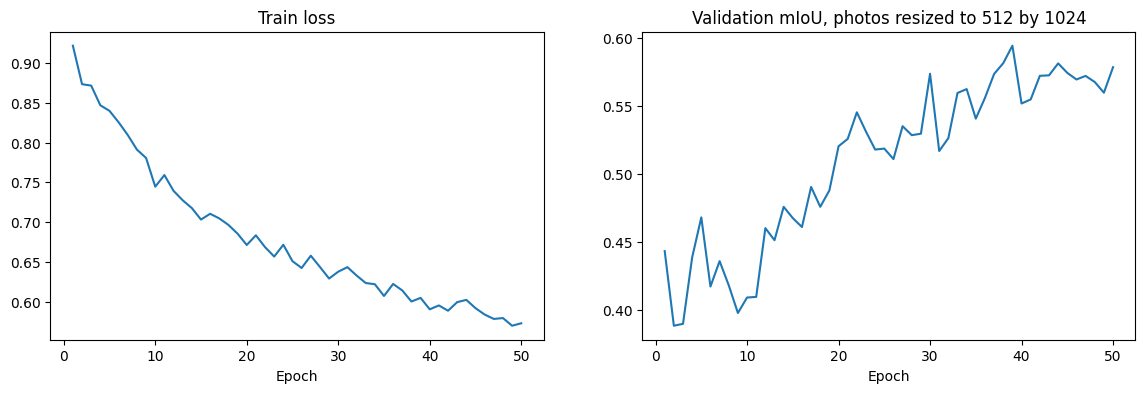

Best epoch: 39, mIoU 0.5944, coral IoU 0.4773, substrate IoU 0.5957, other IoU 0.7102


In [36]:
import matplotlib.pyplot as plt

epoch_numbers = [record["epoch"] for record in history]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(epoch_numbers, [record["train_loss"] for record in history])
axes[0].set_title("Train loss")
axes[0].set_xlabel("Epoch")
axes[1].plot(epoch_numbers, [record["miou"] for record in history])
axes[1].set_title("Validation mIoU, photos resized to {} by {}".format(val_height, val_width))
axes[1].set_xlabel("Epoch")
plt.show()

best_record = max(history, key=lambda record: record["miou"])
print("Best epoch: {}, mIoU {:.4f}, coral IoU {:.4f}, substrate IoU {:.4f}, other IoU {:.4f}".format(
    best_record["epoch"], best_record["miou"], best_record["coral_iou"],
    best_record["substrate_iou"], best_record["other_iou"]))

**Observation**:

## Section 3: E1 table

Question: how does the U-Net trained from scratch compare with the pretrained SegFormer-B0 on the Coralscapes validation set, at the best epoch of each run?

Checks: load the U-Net checkpoints, pick its best epoch by validation mIoU and check that best.pt holds it, read the SegFormer-B0 checkpoints without changing them, pick its best epoch the same way and compare it with the values printed by notebook 02 section 5, then print one table with the parameters, the epochs trained and the IoU of each class. Nothing is trained or written here. Run the setup and settings cells first; this section needs no data, GPU or model.

### Checkpoint files

In [37]:
import datetime

ckpt_root = base_dir + "/Checkpoints"
folders = {"U-Net": ckpt_root + "/stage1_unet", "SegFormer-B0": ckpt_root + "/stage1_segformer_b0"}
print("This section only reads checkpoints; it trains and writes nothing")

for name, folder in folders.items():
    for kind in ["best", "last"]:
        file_path = "{}/{}.pt".format(folder, kind)
        if os.path.isfile(file_path):
            stamp = datetime.datetime.fromtimestamp(os.path.getmtime(file_path)).strftime("%Y-%m-%d %H:%M")
            print("{} {}.pt: found, {:.1f} MB, modified {}".format(
                name, kind, os.path.getsize(file_path) / 1024 ** 2, stamp))
        else:
            print("{} {}.pt: not found".format(name, kind))

This section only reads checkpoints; it trains and writes nothing
U-Net best.pt: found, 22.1 MB, modified 2026-11-18 09:44
U-Net last.pt: found, 22.1 MB, modified 2026-11-18 10:22
SegFormer-B0 best.pt: found, 42.7 MB, modified 2026-11-14 02:54
SegFormer-B0 last.pt: found, 42.7 MB, modified 2026-11-14 03:13


### U-Net: best epoch

In [38]:
# Parameters printed by Section 1
unet_params_section1 = 1927075
buffer_names = ("running_mean", "running_var", "num_batches_tracked")

unet_best_state = torch.load(folders["U-Net"] + "/best.pt", map_location="cpu", weights_only=False)
unet_last_state = torch.load(folders["U-Net"] + "/last.pt", map_location="cpu", weights_only=False)

unet_history = unet_last_state["history"]
unet_best = max(unet_history, key=lambda record: record["miou"])
unet_epochs = unet_last_state["epoch"]
unet_params = sum(tensor.numel() for key, tensor in unet_last_state["model"].items() if not key.endswith(buffer_names))

print("last.pt holds epoch {} and a history of {} entries".format(unet_epochs, len(unet_history)))
print("Best epoch by validation mIoU: {} (mIoU {:.4f})".format(unet_best["epoch"], unet_best["miou"]))
print("best.pt holds epoch {}, the best epoch: {}".format(unet_best_state["epoch"], unet_best_state["epoch"] == unet_best["epoch"]))
print("Parameters counted in the checkpoint: {}, same as Section 1: {}".format(
    unet_params, unet_params == unet_params_section1))
del unet_best_state, unet_last_state

last.pt holds epoch 50 and a history of 50 entries
Best epoch by validation mIoU: 39 (mIoU 0.5944)
best.pt holds epoch 39, the best epoch: True
Parameters counted in the checkpoint: 1927075, same as Section 1: True


### SegFormer-B0: best epoch, read only

In [39]:
# Values printed by notebook 02 section 5 and recorded in the handoff
reference = {"epoch": 37, "miou": 0.6775, "coral_iou": 0.6284, "substrate_iou": 0.6733, "other_iou": 0.7309}

segformer_dir = folders["SegFormer-B0"]
segformer_best_state = torch.load(segformer_dir + "/best.pt", map_location="cpu", weights_only=False)
segformer_last_state = torch.load(segformer_dir + "/last.pt", map_location="cpu", weights_only=False)
segformer_epochs = segformer_last_state["epoch"]
print("last.pt holds epoch {}, best.pt holds epoch {}".format(segformer_epochs, segformer_best_state["epoch"]))

if len(segformer_last_state.get("history", [])) > 0:
    segformer_history = segformer_last_state["history"]
    segformer_best = max(segformer_history, key=lambda record: record["miou"])
    segformer_source = "the checkpoint history"
    print("History: {} entries, epochs {} to {}".format(
        len(segformer_history), segformer_history[0]["epoch"], segformer_history[-1]["epoch"]))
    print("Best epoch by validation mIoU: {} (mIoU {:.4f})".format(segformer_best["epoch"], segformer_best["miou"]))
    print("best.pt holds the best epoch: {}".format(segformer_best_state["epoch"] == segformer_best["epoch"]))
    found = [segformer_best[key] for key in reference]
    print("Same as notebook 02 section 5 (epoch 37, mIoU 0.6775, coral 0.6284, substrate 0.6733, other 0.7309): {}".format(
        found[0] == reference["epoch"] and [round(value, 4) for value in found[1:]] == list(reference.values())[1:]))
else:
    print("The SegFormer-B0 checkpoint holds no history, so the values printed by notebook 02 section 5 are used")
    segformer_best = dict(reference)
    segformer_source = "the values printed by notebook 02 section 5"
del segformer_best_state, segformer_last_state

last.pt holds epoch 50, best.pt holds epoch 37
History: 50 entries, epochs 1 to 50
Best epoch by validation mIoU: 37 (mIoU 0.6775)
best.pt holds the best epoch: True
Same as notebook 02 section 5 (epoch 37, mIoU 0.6775, coral 0.6284, substrate 0.6733, other 0.7309): True


### E1 table

In [40]:
import pandas as pd

rows = []
runs = [
    ("U-Net from scratch", unet_params, unet_epochs, unet_best),
    ("SegFormer-B0 pretrained", segformer_params, segformer_epochs, segformer_best),
]
for label, params, epochs_trained, best in runs:
    rows.append({
        "model": label,
        "parameters": params,
        "epochs trained": epochs_trained,
        "best epoch": best["epoch"],
        "mIoU": best["miou"],
        "coral IoU": best["coral_iou"],
        "substrate IoU": best["substrate_iou"],
        "other IoU": best["other_iou"],
    })

print("E1 on the Coralscapes validation set: 166 photos resized to {} by {}, IoU without the ignored pixels".format(
    val_height, val_width))
print("The test split is not used. U-Net numbers: checkpoint history. SegFormer-B0 numbers: {}".format(segformer_source))
print(pd.DataFrame(rows).round(4).to_string(index=False))

E1 on the Coralscapes validation set: 166 photos resized to 512 by 1024, IoU without the ignored pixels
The test split is not used. U-Net numbers: checkpoint history. SegFormer-B0 numbers: the checkpoint history
                  model  parameters  epochs trained  best epoch   mIoU  coral IoU  substrate IoU  other IoU
     U-Net from scratch     1927075              50          39 0.5944     0.4773         0.5957     0.7102
SegFormer-B0 pretrained     3714915              50          37 0.6775     0.6284         0.6733     0.7309


**Observation**: From the E1 comparison, SegFormer-B0 performed better with 0.6775 mIoU, compared to 0.5944 for U-Net. It also had higher coral IoU (0.6284 vs 0.4773), although U-Net used fewer parameters.